# Векторные модели: мешок слов и TF-IDF

Пусть у нас есть небольшая подборка текстов на разные темы: учеба, еда, поездки и так далее. Хотелось бы, чтобы компьютер мог понять, какие тексты говорят примерно об одном и том же. При этом в текстах на одну тему могут быть разные слова, а одинаковое слово может встречаться в совершенно разных темах.

Чтобы сравнивать такие тексты, их надо перевести в числа. Способов это сделать много; в какой-то период развития NLP об этом писали много статей. Мы сегодня посмотрим на устоявшиеся и проверенные временем статистические подходы:

- Мешок слов;
- TF-IDF;

А на следующей паре поговорим про модели:
- Word2Vec;
- BERT.

И увидим, какую информацию они сохраняют и что теряют.

## План

1. Тексты и общая идея векторизации.
2. Мешок слов (BoW), предобработка и косинусная близость.
3. TF-IDF и сравнение с BoW на большем корпусе.
4. Практика: ключевые слова по TF-IDF и влияние `min_df`.


## Тексты, с которыми будем работать

В файле [`semantic_texts.jsonl`](semantic_texts.jsonl) лежат 24 небольшие заметки: про учебу, еду, поездки, деньги, природу и технику. Это специально написанные учебные тексты, а не выборка реальных новостей. В каждой строке файла — одна запись в формате JSON.

- `doc_id` — ее номер,
- `topic` — тема,

- `title` — заголовок,
- `text` — исходный текст,
- `text_bow_with_stopwords` — готовые леммы со стоп-словами,
- `text_bow_without_stopwords` — готовые леммы без стоп-слов,
- `text_bow` — прежнее имя версии без стоп-слов, сохраненное для совместимости,
- `tokens_w2v` — готовые ключи `лемма_ЧАСТЬРЕЧИ` для Word2Vec на следующей паре.

Категории записаны по-английски: `food`, `study`, `travel`, `finance`, `nature`, `technology`. Названия имеют вид `food_1`, `food_2` и т. д.; нумерация внутри каждой категории начинается с 1.

Тему и заголовок оставим для просмотра результатов. BoW и TF-IDF получат только подготовленную версию текста: иначе мы сами подскажем им, какие документы надо сближать.

Для начала установим библиотеки.

Мешок слов и TF-IDF работают без скачивания моделей.

In [ ]:
# Установим библиотеки для векторизации и графиков
!pip install -q "numpy<3" "pandas<3" "scikit-learn<2" "matplotlib<4"

In [ ]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics.pairwise import cosine_similarity

from sklearn.feature_extraction.text import (
    CountVectorizer, TfidfVectorizer, TfidfTransformer,
)
from sklearn.preprocessing import normalize


Прочитаем готовый файл с исходными и предобработанными текстами.

Если таблица — последнее выражение ячейки, Jupyter покажет ее автоматически. Поэтому будем выводить каждую таблицу в отдельной ячейке.

In [ ]:
!wget https://raw.githubusercontent.com/hse-ling-python/hse-ling_26-27/refs/heads/main/files/semantic_texts.jsonl
!wget https://raw.githubusercontent.com/hse-ling-python/hse-ling_26-27/refs/heads/main/files/wikipedia_sample.jsonl

--2026-10-11 17:33:05--  https://raw.githubusercontent.com/hse-ling-python/hse-ling_26-27/refs/heads/main/files/semantic_texts.jsonl
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 67648 (66K) [text/plain]
Saving to: ‘semantic_texts.jsonl.1’

semantic_texts.json 100%[===================>]  66.06K  --.-KB/s    in 0.001s  

2026-10-11 17:33:05 (44.0 MB/s) - ‘semantic_texts.jsonl.1’ saved [67648/67648]

--2026-10-11 17:33:05--  https://raw.githubusercontent.com/hse-ling-python/hse-ling_26-27/refs/heads/main/files/wikipedia_sample.jsonl
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP

In [ ]:
path = "semantic_texts.jsonl"
docs = pd.read_json(path, lines=True)
texts = docs["text"].tolist()

print(docs.shape)
docs.sample(5, random_state=42)

(24, 8)


,doc_id,topic,title,text,text_bow,tokens_w2v,text_bow_with_stopwords,text_bow_without_stopwords
8,d09,travel,travel_1,После полуночи электрички из аэропорта уже не ...,полуночь электричка аэропорт ходить центр горо...,"[после_ADP, полуночь_NOUN, электричка_NOUN, из...",после полуночь электричка из аэропорт уже не х...,полуночь электричка аэропорт ходить центр горо...
16,d17,nature,nature_1,Рядом с тропой из-под камней бьет холодный клю...,рядом тропа камень бить холодный ключ родник т...,"[рядом_ADV, с_ADP, тропа_NOUN, из-под_ADP, кам...",рядом с тропа камень бить холодный ключ у родн...,рядом тропа камень бить холодный ключ родник т...
0,d01,food,food_1,Для овощного супа сначала нарежьте лук и морко...,овощной суп сначала нарезать лук морковь затем...,"[для_ADP, овощной_ADJ, суп_NOUN, сначала_ADV, ...",для овощной суп сначала нарезать лук и морковь...,овощной суп сначала нарезать лук морковь затем...
18,d19,nature,nature_3,На школьной грядке посадили лук и каждую недел...,школьный грядка посадить лук каждый неделя изм...,"[на_ADP, школьный_ADJ, грядка_NOUN, посадить_V...",на школьный грядка посадить лук и каждый недел...,школьный грядка посадить лук каждый неделя изм...
11,d12,travel,travel_4,Для короткой поездки удобно собрать вещи в неб...,короткий поездка удобно собрать вещь небольшой...,"[для_ADP, короткий_ADJ, поездка_NOUN, удобно_A...",для короткий поездка удобно собрать вещь в неб...,короткий поездка удобно собрать вещь небольшой...


In [ ]:
# Прочитаем несколько полных текстов, а не только их заголовки
for row in docs.iloc[[0, 4, 8, 12, 16, 20]].itertuples():
    print(f"{row.doc_id}. {row.title}\n{row.text}\n")

d01. food_1
Для овощного супа сначала нарежьте лук и морковь, затем слегка обжарьте их в кастрюле. Добавьте картофель, воду и чечевицу и варите до мягкости. Мясо и мясной бульон для этого рецепта не нужны: густоту и сытность дает чечевица.

d05. study_1
Подготовку к экзамену полезно распределить на несколько дней, а не оставлять на последнюю ночь. После чтения конспекта закройте его и попробуйте самостоятельно ответить на вопросы по теме. Вернитесь к сложным вопросам на следующий день и через неделю: повторение с интервалами помогает удержать материал в памяти.

d09. travel_1
После полуночи электрички из аэропорта уже не ходят, но до центра города можно доехать ночным автобусом. Остановка находится у выхода из зала прилета, а интервал движения составляет около получаса. Если багажа много, можно заказать такси; стоимость поездки стоит проверить до посадки.

d13. finance_1
Если банковская карта потерялась, сначала заблокируйте ее в приложении банка или по телефону поддержки. После блокир

## Общая идея векторизации

Каждому тексту поставим в соответствие вектор — упорядоченный набор чисел. Это позволит компьютеру работать с ним как с математическим объектом, применять сложение, функцию логарифма или любое другое преобразование. И сравнивать, как мы сравниваем векторы в геометрии.

Чего бы мы хотели от таких векторов?

- Векторы близких по смыслу текстов хотелось бы направить примерно в одну сторону;
- Векторы разных по смыслу текстов — в разные;
- Эти векторы должно быть легко хранить;
- И дешево получать.

Понятное дело, что получить все и сразу, скорее всего, не получится. Чаще всего нам придется выбирать между качеством и стоимостью, как и всегда.

## Мешок слов

**Мешок слов (Bag of Words, BoW)** представляет текст через частоты слов. Сначала собираем словарь корпуса, затем для каждого текста считаем, сколько раз встретилось каждое слово. Координата вектора здесь имеет понятный смысл: это частота конкретного слова из словаря.

Порядок слов при этом исчезает. «Студент объясняет преподавателю» и «Преподаватель объясняет студенту» говорят о разных ситуациях, но после лемматизации их мешки слов будут одинаковыми.

Слова внутри вектора могут быть упорядочены как угодно. Главное, чтобы внутри векторов для одного корпуса порядок был одинаковый, иначе вектора будут несравнимы. Но чаще всего порядок либо алфавитный, либо частотный.

In [ ]:
# Посмотрим на маленький мешок слов, в котором видна каждая координата

small_texts = ["студент читает книгу", "студент читает конспект", "поезд едет"]
small_bow = CountVectorizer()
small_matrix = small_bow.fit_transform(small_texts)
pd.DataFrame(small_matrix.toarray(), columns=small_bow.get_feature_names_out())

,едет,книгу,конспект,поезд,студент,читает
0,0,1,0,0,1,1
1,0,0,1,0,1,1
2,1,0,0,1,0,0


### Зачем нужна предобработка?

Для мешка слов «книга» и «книгу» — разные признаки, а это может сильно искажать статистику. Поэтому при работе с ним обычно проводят стандартную предобработку:
- Токенизируем;
- Убираем пунктуацию и часто еще неалфавитные символы (`s.isalpha()`);
- Приводим к нижнему регистру;
- Лемматизируем;
- Можно убрать стоп-слова, но тут уже зависит от задачи: среди них может оказаться «не», а для смысла отрицание бывает очень важным.

В этой тетрадке она уже выполнена заранее: мы просто прочитаем готовое поле со стоп-словами или без них. Для сравнения вариантов достаточно изменить `bow_text_field` в следующей ячейке и заново выполнить ячейки векторизации. Код предобработки разберем отдельно.

In [ ]:
# Выберем готовую версию: можно заменить на "text_bow_with_stopwords"
bow_text_field = "text_bow_without_stopwords"
clean_texts = docs[bow_text_field].tolist()
print(texts[0])
print(clean_texts[0])

Для овощного супа сначала нарежьте лук и морковь, затем слегка обжарьте их в кастрюле. Добавьте картофель, воду и чечевицу и варите до мягкости. Мясо и мясной бульон для этого рецепта не нужны: густоту и сытность дает чечевица.
овощной суп сначала нарезать лук морковь затем слегка обжарить кастрюля добавить картофель вода чечевица варить мягкость мясо мясной бульон это рецепт нужный густота сытность давать чечевица


Теперь соберем мешок слов для всех наших текстов. В строках будут тексты, в столбцах — слова, а в ячейках — число их употреблений.

In [ ]:
# Посмотрим на частоты выбранных слов во всех текстах
bow = CountVectorizer()
X_bow = bow.fit_transform(clean_texts)

feature_words = ["суп", "лук", "книга", "билет", "ключ", "сеть"]
bow_table = pd.DataFrame(X_bow.toarray(), index=docs.title, columns=bow.get_feature_names_out())
bow_table[feature_words]

,суп,лук,книга,билет,ключ,сеть
title,,,,,,
food_1,1,1,0,0,0,0
food_2,0,0,0,0,0,0
food_3,0,0,0,0,0,0
food_4,0,0,0,0,0,0
study_1,0,0,0,0,0,0
study_2,0,0,1,1,0,0
study_3,0,0,0,0,0,0
study_4,0,0,0,0,0,0
travel_1,0,0,0,0,0,0


### Насколько похожи тексты?

Векторы у нас есть. Теперь хочется понять, какие тексты получились похожими. Будем сравнивать направления их векторов с помощью **косинусной близости (cosine similarity)**.

Чем больше значение, тем ближе направления:

- 1 — векторы направлены одинаково;
- 0 — под прямым углом друг к другу;
- −1 — в противоположные стороны.

Для мешка слов значения будут от 0 до 1, потому что все частоты неотрицательные. Это не вероятность: близость 0.8 не означает «80% общего смысла». Значения разных способов векторизации тоже не стоит сравнивать напрямую.

Посчитаем близость каждой пары текстов и покажем ее цветом. И по строкам, и по столбцам будут наши 24 текста. Чем теплее цвет, тем больше близость. На диагонали каждый текст сравнивается с собой, поэтому там будет 1.

In [ ]:
# Нарисуем близость каждой пары текстов (можно не вникать)

similarity_cmap = LinearSegmentedColormap.from_list(
    "blue_white_red", ["#3b4cc0", "white", "#b40426"], N=257
)

def plot_similarity(matrix, title, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(cosine_similarity(matrix), vmin=-1, vmax=1, cmap=similarity_cmap)
    ax.set(title=title, xlabel="Документ", ylabel="Документ")
    ax.set_xticks(range(len(docs)), docs.title, rotation=90, fontsize=7)
    ax.set_yticks(range(len(docs)), docs.title, fontsize=7)
    for border in [3.5, 7.5, 11.5, 15.5, 19.5]:
        ax.axhline(border, color="black", linewidth=0.5)
        ax.axvline(border, color="black", linewidth=0.5)
    return image

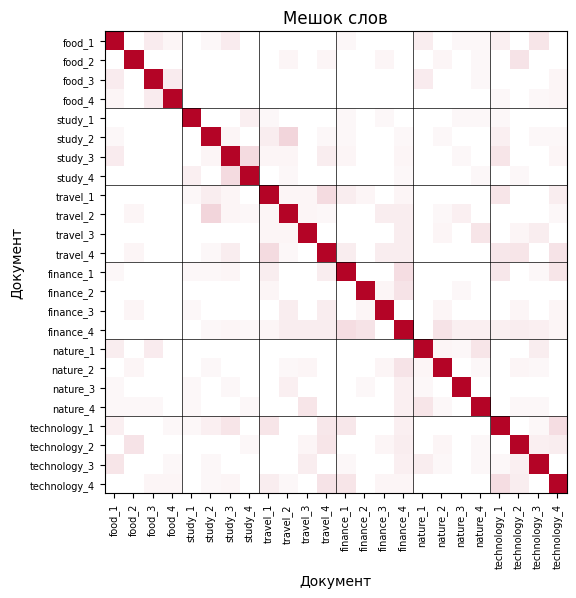

In [ ]:
# Посмотрим на близость текстов в представлении BoW
plot_similarity(X_bow, "Мешок слов")
plt.show()

Документы расположены по темам, по четыре в каждой. Если модель сближает тексты одной темы, на диагонали будут заметны теплые квадраты размером 4 × 4. Сама диагональ мало что говорит о качестве: любой ненулевой вектор совпадает с собой. Интереснее клетки вокруг нее и похожие документы из разных тем.

Здесь мы почти ничего не видим: есть слабые окрашенные квадратики, но они расположены очень хаотично.

In [ ]:
# Применим BoW к уже подготовленным текстам
def encode_bow(items):
    return bow.transform(items)

## TF-IDF

В мешке слов все слова считаются по одному правилу. Но часто встречающееся почти везде слово обычно хуже отличает один документ от другого, чем редкое. **TF-IDF** меняет веса слов: учитывает частоту в тексте и редкость в корпусе.

**TF-IDF** (term frequency — inverse document frequency) состоит из двух частей: частоты слова в конкретном тексте и его редкости во всём корпусе.

**TF (term frequency)** — доля употреблений слова $t$ в документе $d$:

$$
\operatorname{tf}(t,d)=\frac{\operatorname{count}(t,d)}{\sum_{t'}\operatorname{count}(t',d)}.
$$

Здесь:
- $\operatorname{count}(t,d)$ — сколько раз слово $t$ встретилось в документе $d$;
- $\sum_{t'}\operatorname{count}(t',d)$ — общее число слов в документе, включая повторения.

Например, если слово «экзамен» встретилось 3 раза в тексте из 100 слов, его TF равен $3/100=0.03$.

**IDF (inverse document frequency)** — обратная документная частота. Она показывает, насколько слово редко встречается в документах корпуса:

$$
\operatorname{idf}(t)=\log\frac{N}{\operatorname{df}(t)}.
$$

Здесь:
- $N$ — общее число документов в корпусе;
- $\operatorname{df}(t)$ — число документов, в которых слово $t$ встретилось хотя бы один раз.

Чем меньше документов содержат слово, тем больше его IDF. Если слово встречается во всех документах, его IDF равен $\log 1=0$: оно не помогает отличить один документ от другого.

Итоговый вес — произведение этих двух величин:

$$
\operatorname{tfidf}(t,d)=\operatorname{tf}(t,d)\cdot\operatorname{idf}(t).
$$

Таким образом, большой вес получают слова, которые часто встречаются в конкретном тексте, но редко — в остальных документах корпуса.

У TF-IDF есть несколько вариантов расчёта. В `TfidfVectorizer` по умолчанию используются абсолютная частота слова и сглаженный IDF (чтобы случайно не получить ноль в знаменателе или под логарифмом):

$$
\operatorname{tf}(t,d)=\operatorname{count}(t,d),
$$

$$
\operatorname{idf}(t)=\log\frac{1+N}{1+\operatorname{df}(t)}+1.
$$

После их умножения весь вектор документа нормируется: каждая координата делится на его длину.

$$
\widehat{w}_{t,d}=\frac{w_{t,d}}{\sqrt{\sum_{t'}w_{t',d}^{\,2}}},
\qquad
w_{t,d}=\operatorname{tf}(t,d)\cdot\operatorname{idf}(t).
$$

In [ ]:
# Изменим веса, сохранив те же тексты и ту же предобработку
tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(clean_texts)

idf = pd.Series(tfidf.idf_, index=tfidf.get_feature_names_out(), name="idf")
pd.concat([idf.nsmallest(6), idf.nlargest(6)]).to_frame()

,idf
проверить,2.021651
мочь,2.272966
вода,2.609438
затем,2.609438
телефон,2.609438
всё,2.832581
абзац,3.525729
абонемент,3.525729
автобус,3.525729
адаптер,3.525729


In [ ]:
# Сравним веса тех же слов в тех же текстах
tfidf_table = pd.DataFrame(X_tfidf.toarray(), index=docs.title, columns=tfidf.get_feature_names_out())
tfidf_table[feature_words].round(3)

,суп,лук,книга,билет,ключ,сеть
title,,,,,,
food_1,0.198,0.176,0.00,0.000,0.000,0.000
food_2,0.000,0.000,0.00,0.000,0.000,0.000
food_3,0.000,0.000,0.00,0.000,0.000,0.000
food_4,0.000,0.000,0.00,0.000,0.000,0.000
study_1,0.000,0.000,0.00,0.000,0.000,0.000
study_2,0.000,0.000,0.19,0.168,0.000,0.000
study_3,0.000,0.000,0.00,0.000,0.000,0.000
study_4,0.000,0.000,0.00,0.000,0.000,0.000
travel_1,0.000,0.000,0.00,0.000,0.000,0.000


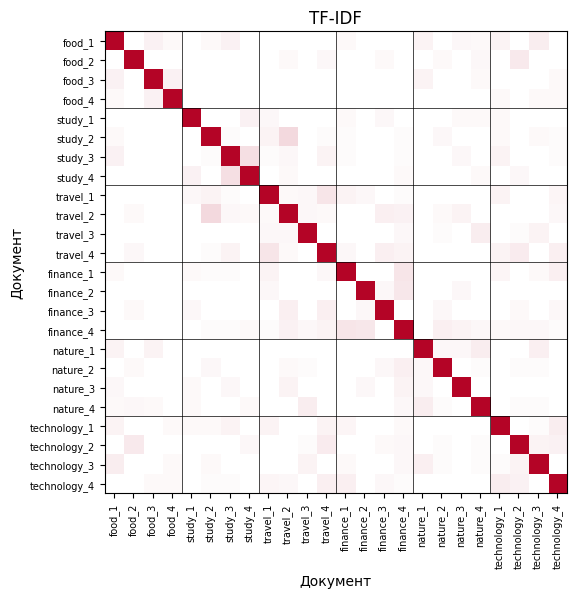

In [ ]:
# Посмотрим, как изменились отношения между текстами
plot_similarity(X_tfidf, "TF-IDF")
plt.show()

In [ ]:
# Сравним частоты и веса слов внутри одного документа
terms = tfidf.get_feature_names_out()
weights = pd.DataFrame({
    "слово": terms,
    "BoW": X_bow[0].toarray().ravel(),
    "TF-IDF": X_tfidf[0].toarray().ravel(),
})
weights.sort_values("TF-IDF", ascending=False).head(10)

,слово,BoW,TF-IDF
505,чечевица,2,0.396982
229,обжарить,1,0.198491
200,мясо,1,0.198491
239,овощной,1,0.198491
29,варить,1,0.198491
23,бульон,1,0.198491
194,морковь,1,0.198491
207,нарезать,1,0.198491
66,густота,1,0.198491
376,рецепт,1,0.198491


In [ ]:
# Применим TF-IDF к уже подготовленным текстам
def encode_tfidf(items):
    return tfidf.transform(items)

TF-IDF изменил важность слов, но не превратил их в значения. Если в одном тексте «автомобиль», а в другом только «машина», общая координата не появится. Порядок слов TF-IDF тоже не учитывает, пока мы используем отдельные слова.

### Что меняется на большем корпусе?

В коротких заметках многие слова встречаются всего один раз, и их IDF почти не различается. Возьмем **500 фрагментов русской Википедии** и посмотрим, что происходит, когда словарь и тематика становятся разнообразнее.

В файле [`wikipedia_sample.jsonl`](wikipedia_sample.jsonl) сохранены первые 500 записей русской части [корпуса Wikimedia](https://huggingface.co/datasets/wikimedia/wikipedia), срез `20231101.ru`. Из каждой статьи взяты первые 250 слов или весь текст, если он короче. Это не случайная и не сбалансированная выборка всей Википедии. Здесь есть и короткие страницы со списками значений, и начала больших статей.

Для векторизации используем готовое поле `text_bow_with_stopwords`: здесь сохранены леммы без пунктуации, но со стоп-словами, как и в исходном сравнении на большем корпусе.

В файле есть и версия `text_bow_without_stopwords`; ее можно выбрать в следующей ячейке векторизации.

In [ ]:
# Прочитаем фрагменты из локального файла, без скачивания корпуса на паре
wiki_path = "wikipedia_sample.jsonl"
wiki_docs = pd.read_json(wiki_path, lines=True)
print("Документов:", len(wiki_docs))
print("Слов в корпусе:", sum(len(text.split()) for text in wiki_docs.text))
wiki_docs.head()

Документов: 500
Слов в корпусе: 116784


,doc_id,title,url,text,text_bow,text_bow_with_stopwords,text_bow_without_stopwords
0,wiki_7,Литва,https://ru.wikipedia.org/wiki/%D0%9B%D0%B8%D1%...,"Литва́ ( ), официальное название — Лито́вская ...",официальный название государство расположить в...,официальный название государство расположить в...,официальный название государство расположить с...
1,wiki_9,Россия,https://ru.wikipedia.org/wiki/%D0%A0%D0%BE%D1%...,"Росси́я, или Росси́йская Федера́ция (), — госу...",или государство в восточный европа и северный ...,или государство в восточный европа и северный ...,государство восточный европа северный азия рос...
2,wiki_10,Слоновые,https://ru.wikipedia.org/wiki/%D0%A1%D0%BB%D0%...,"Слоно́вые, или слоны́ , — семейство класса мле...",или семейство класс млекопитающее из отряд хоб...,или семейство класс млекопитающее из отряд хоб...,семейство класс млекопитающее отряд хоботный н...
3,wiki_11,Мамонты,https://ru.wikipedia.org/wiki/%D0%9C%D0%B0%D0%...,Ма́монты () — вымерший род млекопитающих отряд...,вымереть родиться млекопитающее отряд хоботный...,вымереть родиться млекопитающее отряд хоботный...,вымереть родиться млекопитающее отряд хоботный...
4,wiki_15,Красная книга,https://ru.wikipedia.org/wiki/%D0%9A%D1%80%D0%...,Кра́сная кни́га — аннотированный список редких...,аннотировать список редкий и находиться под уг...,аннотировать список редкий и находиться под уг...,аннотировать список редкий находиться угроза и...


In [ ]:
# Прочитаем один фрагмент полностью
print(wiki_docs.loc[wiki_docs.title.eq("Хроматография"), "text"].iloc[0])

Хроматогра́фия (от — «цвет») — метод разделения и анализа смесей веществ, а также изучения физико-химических свойств веществ. Основан на распределении веществ между двумя фазами — неподвижной (твёрдая фаза или жидкость, связанная на инертном носителе) и подвижной (газовая или жидкая фаза, элюент). Название метода связано с первыми экспериментами по хроматографии, в ходе которых разработчик метода Михаил Цвет разделял ярко окрашенные растительные пигменты. История метода Метод хроматографии был впервые применён русским учёным-ботаником Михаилом Семеновичем Цветом в 1900 году. Он использовал колонку, заполненную карбонатом кальция, для разделения пигментов растительного происхождения. Первое сообщение о разработке метода хроматографии было сделано Цветом 30 декабря 1901 года на XI Съезде естествоиспытателей и врачей в С.-Петербурге. Первая печатная работа по хроматографии была опубликована в 1903 году, в журнале «Труды Варшавского общества естествоиспытателей». Впервые термин «хроматогра

По формуле выше видно, что в `TfidfVectorizer` с настройками по умолчанию один из множителей — TF — это буквально матрица частот, которая строится в BoW. При этом IDF тоже можно вычислить по этой матрице:

- Превращаем все числа `> 0` в единицы и суммируем по столбцам. Получаем вектор: для каждого слова — число документов, где оно встречается, то есть $\operatorname{df}(t)$.
- К каждому числу прибавляем 1 и делим **число документов плюс 1 на полученное значение**: $\frac{N+1}{\operatorname{df}(t)+1}$.
- Берём натуральный логарифм и прибавляем 1. Получаем вектор IDF: $\log\frac{N+1}{\operatorname{df}(t)+1}+1$.
- Умножаем каждый столбец исходной матрицы частот на соответствующее значение IDF. Мысленно можно представить, что мы повторили вектор IDF для каждой строки, но создавать такую матрицу в памяти не нужно.
- Наконец, нормируем каждую ненулевую строку: делим её на длину получившегося вектора. Именно такую матрицу возвращает `TfidfVectorizer` по умолчанию.

Сделаем сравнение на основе описанного выше:
- Возьмем исходные предобработанные тексты;
- Посчитаем для них частоты через BOW (как делали выше);
- Используем TfidfTransformer: он получает уже готовую матрицу частот и строит по ней полную tf-idf матрицу. В итоге это те же веса, которые вычисляет TfidfVectorizer, просто два шага здесь разделены, а мы имеем возможность гарантировать, что слова в матрицах будут в одинаковом порядке.

Стоп-слова пока оставим. Так будет видно, что происходит с распространенными словами.

In [ ]:
# считаем частоты
# Можно выбрать "text_bow_without_stopwords" для сравнения
wiki_bow_text_field = "text_bow_with_stopwords"
wiki_clean = wiki_docs[wiki_bow_text_field].tolist()
wiki_bow = CountVectorizer()
wiki_counts = wiki_bow.fit_transform(wiki_clean)

# строим на их основе tf-idf
wiki_transformer = TfidfTransformer()
wiki_tfidf = wiki_transformer.fit_transform(wiki_counts)

# нормализуем частоты, чтобы при сравнении с tf-idf числа были одного порядка
wiki_bow_normalized = normalize(wiki_counts)

# получаем список слов
wiki_terms = wiki_bow.get_feature_names_out()

print("Размер обеих матриц:", wiki_counts.shape)

Размер обеих матриц: (500, 16120)


In [ ]:
# Сравним распространенность слова и его IDF
term_stats = pd.DataFrame({
    "документов со словом": np.asarray((wiki_counts > 0).sum(axis=0)).ravel(),
    "IDF": wiki_transformer.idf_,
}, index=wiki_terms)
term_stats["доля документов"] = term_stats["документов со словом"] / len(wiki_docs)

words = ["это", "который", "год", "язык", "хроматография", "мамонт"]
term_stats.loc[words].sort_values("IDF", ascending=False).round(3)

,документов со словом,IDF,доля документов
мамонт,1,6.523,0.002
хроматография,10,4.819,0.020
язык,72,2.926,0.144
это,210,1.865,0.420
который,291,1.540,0.582
год,303,1.500,0.606


В статье «Хроматография» сравните слова «год» и «хроматография». Их частоты в самом фрагменте одинаковы, но «год» встречается во множестве других статей. В TF-IDF они уже не должны иметь одинаковый вес. При этом частое слово не исчезает совсем: IDF уменьшает его относительную важность, а не удаляет его.

In [ ]:
# Сравним веса конкретных слов в одной статье
article_index = wiki_docs.index[wiki_docs.title.eq("Хроматография")][0]
article_weights = pd.DataFrame({
    "частота": wiki_counts[article_index].toarray().ravel(),
    "BoW (normalized)": wiki_bow_normalized[article_index].toarray().ravel(),
    "TF-IDF": wiki_tfidf[article_index].toarray().ravel(),
    "IDF": wiki_transformer.idf_,
}, index=wiki_terms)

words = ["год", "хроматография", "метод", "вещество", 'быть']
# Если слово удалено из словаря, его веса и IDF не определены: покажем NaN
article_weights.reindex(words).round(3)

,частота,BoW (normalized),TF-IDF,IDF
год,9,0.374,0.150,1.500
хроматография,9,0.374,0.483,4.819
метод,11,0.457,0.412,3.366
вещество,4,0.166,0.127,2.860
быть,4,0.166,0.070,1.561


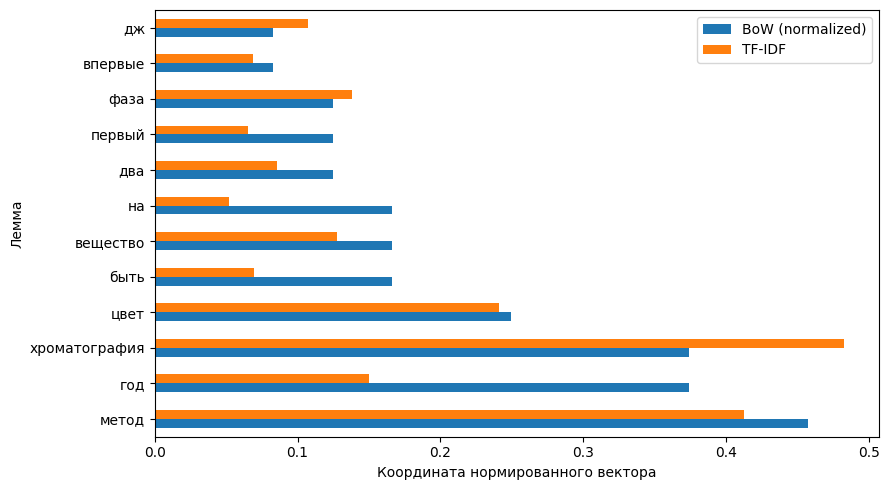

In [ ]:
# На общей шкале покажем, как изменились самые частые слова статьи
top_words = article_weights.nlargest(12, "частота").index
article_weights.loc[top_words, ["BoW (normalized)", "TF-IDF"]].plot.barh(figsize=(9, 5))
plt.xlabel("Координата нормированного вектора")
plt.ylabel("Лемма")
plt.tight_layout()
plt.show()

### Тематические группы на большем корпусе

Возьмем девять статей: по три о языке, химии и планетах. Веса TF-IDF уже посчитаны по всем 500 фрагментам.

In [ ]:
# Выберем по три статьи на каждую тему
wiki_titles = ["Лингвистика", "Русский язык", "Эсперанто",
               "Хроматография", "Жидкостная хроматография", "Хроматографическая колонка",
               "Марс", "Венера", "Сатурн"]
wiki_indices = [wiki_docs.index[wiki_docs.title.eq(title)][0] for title in wiki_titles]
wiki_docs.loc[wiki_indices, ["title", "text"]]

,title,text
7,Лингвистика,"Лингви́стика (от «язык»), языкозна́ние, языков..."
198,Русский язык,Ру́сский язы́к () — язык восточнославянской гр...
84,Эсперанто,Эспера́нто () — наиболее распространённый план...
87,Хроматография,Хроматогра́фия (от — «цвет») — метод разделени...
94,Жидкостная хроматография,"Жидкостная хроматография — хроматография, в ко..."
96,Хроматографическая колонка,Хроматографи́ческая коло́нка — устройство для ...
483,Марс,Марс — четвёртая по удалённости от Солнца и се...
471,Венера,Вене́ра — вторая по удалённости от Солнца и ше...
480,Сатурн,Сату́рн — шестая планета по удалённости от Сол...


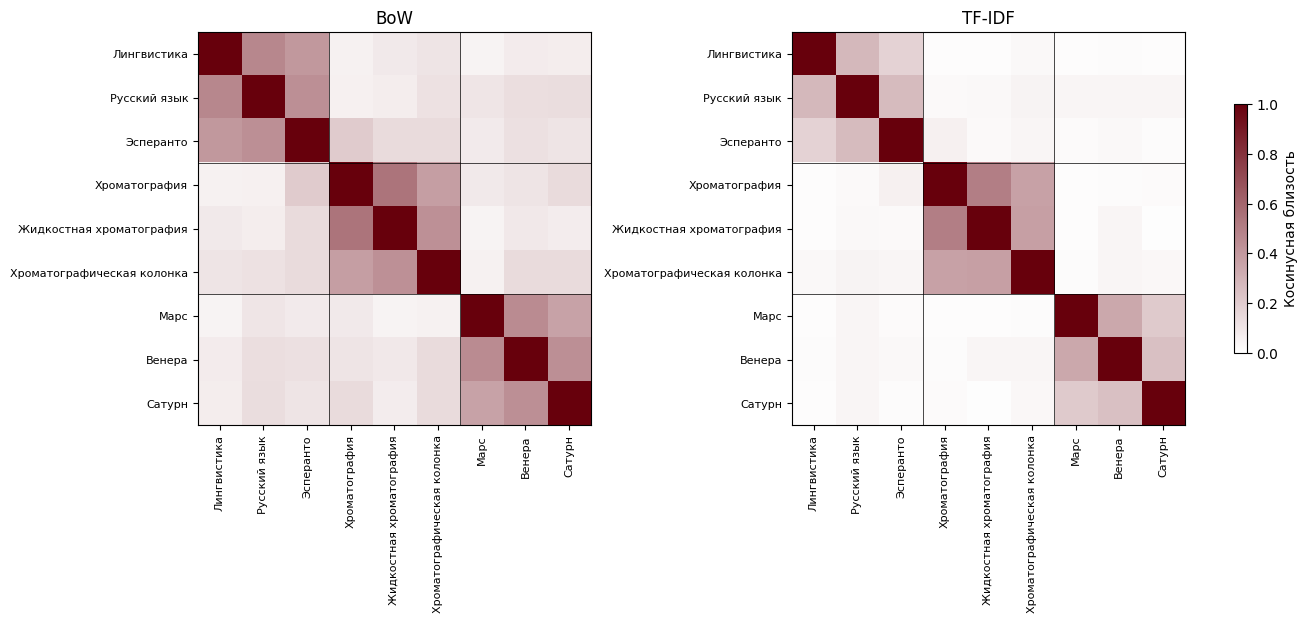

In [ ]:
# Сравним одни и те же тематические группы на общей цветовой шкале
frequency_cmap = LinearSegmentedColormap.from_list(
    "white_red", ["white", plt.get_cmap("Reds")(1.0)], N=257
)
fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
for ax, name, matrix in zip(axes, ["BoW", "TF-IDF"], [wiki_counts, wiki_tfidf]):
    similarities = cosine_similarity(matrix[wiki_indices])
    image = ax.imshow(similarities, vmin=0, vmax=1, cmap=frequency_cmap)
    ax.set_title(name)
    ax.set_xticks(range(9), wiki_titles, rotation=90, fontsize=8)
    ax.set_yticks(range(9), wiki_titles, fontsize=8)
    for border in [2.5, 5.5]:
        ax.axhline(border, color="black", linewidth=0.5)
        ax.axvline(border, color="black", linewidth=0.5)
fig.colorbar(image, ax=axes.tolist(), label="Косинусная близость", shrink=0.6)
plt.show()

## Практика 1

Мы уже посмотрели, как TF-IDF меняет веса слов. Теперь попробуем использовать эти веса, чтобы понять, о чем текст: будем считать ключевыми слова с самым большим TF-IDF.

Возьмите корпус Википедии и уже посчитанную для него матрицу `wiki_tfidf`. Порядок слов в ее столбцах можно узнать через `wiki_terms`.

1. Выберите три текста на разные темы. Прочитайте их и для каждого выпишите по пять слов, которые вы сами считаете ключевыми.
2. Найдите пять-десять слов с наибольшим TF-IDF для каждого выбранного текста. Учитывайте только слова с ненулевым весом. Выведите слова вместе с их весами в порядке убывания.
3. Сравните результат со своим списком. Какие слова помогают понять тему? Какие получили большой вес, но мало говорят о содержании?
4. Для тех же текстов найдите пять-десять самых частотных слов по матрице `wiki_counts`. Сравните два списка: что изменилось после учета IDF?

Для получения строки разреженной матрицы в виде обычного одномерного массива можно использовать `wiki_tfidf[index].toarray().ravel()`. Метод `argsort()` поможет получить индексы элементов в порядке возрастания их значений.

Напишите функцию `get_keywords(index, top_n=10)`, которая принимает номер текста и возвращает таблицу с ключевыми словами и их весами.

In [ ]:
# Ваш код

## Практика 2

Пересчитайте TF-IDF, добавив в `CountVectorizer` параметр `min_df=3`: теперь в словарь попадут только слова, встретившиеся хотя бы в трех документах. После этого заново получите названия столбцов и ключевые слова для тех же текстов.

- Какие слова исчезли? Были ли среди них полезные?
- Стали ли списки лучше отражать темы текстов?
- Почему редкое слово может получить большой вес, даже если оно не главное в тексте?
- Можно ли считать ключевые слова свойством только самого текста или результат зависит и от остальных документов корпуса?

Сформулируйте короткий вывод: когда TF-IDF помогает выделить ключевые слова и в каких случаях его результат стоит проверять вручную.

In [ ]:
# Ваш код

## Сравнение BoW и TF-IDF

| Что сравниваем | Мешок слов (BoW) | TF-IDF |
|---|---|---|
| Идея | Считаем, сколько раз каждое слово встретилось в тексте | Учитываем частоту слова в тексте и его редкость в корпусе |
| Что значит координата | Число употреблений слова | Вес слова с учетом IDF и нормировки |
| Что зависит от корпуса | Словарь | Словарь и IDF: при изменении корпуса веса могут измениться |
| Размер и хранение | Размер словаря; разреженная матрица | Размер словаря; разреженная матрица |
| Плюсы | Просто построить и объяснить; удобно анализировать частоты | Снижает относительную важность слов, встречающихся во многих документах; помогает выделять характерную лексику |
| Минусы | Частые общие слова могут мешать сравнению; сами частоты не показывают, насколько слово характерно для документа | Редкое слово может получить большой вес, даже если оно не главное; результат зависит от состава корпуса |
| Формы слова | Без предобработки «книга» и «книгу» — разные признаки | Та же проблема: изменение весов не заменяет предобработку |
| Синонимы | «Автомобиль» и «машина» — разные координаты | IDF не связывает синонимы: координаты остаются разными |
| Порядок слов | Теряется при использовании отдельных слов | Тоже теряется при использовании отдельных слов |
| Незнакомые слова | Слова вне построенного словаря игнорируются | Слова вне построенного словаря игнорируются |
| Где полезно начать | Анализ частот, простой исходный способ сравнения текстов | Выделение ключевых слов, поиск и сравнение текстов с общей характерной лексикой |

Оба метода описывают лексику текста, но не гарантируют понимания его смысла. TF-IDF меняет важность слов, а не устраняет ограничения мешка слов. Выбор метода стоит проверять на конкретной задаче: какие тексты он сближает и соответствует ли это нашим ожиданиям.
